# Exploration (not part of the pipeline)

Use this notebook to look at the data and at a finished run. Training and submissions are done with `scripts/train.py` and `scripts/make_submission.py` so every result is saved with its config.

In [1]:
import sys
from pathlib import Path

# notebooks/ is one level below the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import DATA_RAW, RUNS_DIR
from src.corpus_pairs import read_corpus
from src.embeddings import nearest_neighbors, normalize_rows, pair_cosines, plot_pca
from src.runs import load_run

## 1. The data

In [2]:
context_train = pd.read_csv(DATA_RAW / 'context_train.csv')
test = pd.read_csv(DATA_RAW / 'test.csv')
print('context_train:', context_train.shape, '| test:', test.shape)
all_tokens = sorted(set(context_train['center_token']) | set(context_train['context_token']))
print('vocabulary size:', len(all_tokens))
context_train.head()

context_train: (300000, 2) | test: (1200, 3)
vocabulary size: 900


,center_token,context_token
0,tok_0255,tok_0099
1,tok_0777,tok_0455
2,tok_0512,tok_0468
3,tok_0022,tok_0242
4,tok_0681,tok_0584


In [3]:
segments = read_corpus(DATA_RAW / 'train_corpus.txt')
for i, seg in enumerate(segments, start=1):
    print(f'Segment {i}: {len(seg):,} tokens, first 10: {seg[:10]}')

Segment 1: 86,191 tokens, first 10: ['tok_0252', 'tok_0521', 'tok_0712', 'tok_0572', 'tok_0210', 'tok_0148', 'tok_0252', 'tok_0567', 'tok_0128', 'tok_0352']
Segment 2: 67,795 tokens, first 10: ['tok_0023', 'tok_0780', 'tok_0797', 'tok_0725', 'tok_0886', 'tok_0094', 'tok_0892', 'tok_0713', 'tok_0023', 'tok_0659']
Segment 3: 20,072 tokens, first 10: ['tok_0023', 'tok_0571', 'tok_0699', 'tok_0706', 'tok_0886', 'tok_0094', 'tok_0023', 'tok_0699', 'tok_0023', 'tok_0571']
Segment 4: 45,703 tokens, first 10: ['tok_0613', 'tok_0023', 'tok_0886', 'tok_0032', 'tok_0644', 'tok_0644', 'tok_0644', 'tok_0644', 'tok_0704', 'tok_0704']


In [4]:
# How often does each token appear as a center? Rare tokens get fewer updates.
counts = context_train['center_token'].value_counts()
counts.describe()

count      900.000000
mean       333.333333
std       1137.381673
min         28.000000
25%         57.000000
50%         87.000000
75%        183.250000
max      18746.000000
Name: count, dtype: float64

## 2. Look at a finished run

The cell below picks the newest run folder. Change `run_dir` to compare runs.

In [5]:
run_dirs = sorted(p for p in RUNS_DIR.iterdir() if p.is_dir())
run_dir = run_dirs[-1]
print('Run:', run_dir.name)

E, token_to_idx = load_run(run_dir)
idx_to_token = {i: t for t, i in token_to_idx.items()}
E_norm = normalize_rows(E)
pd.read_csv(run_dir / 'loss_history.csv')

Run: 20261114_191835_baseline


,epoch,train_loss,val_loss
0,1,5.602571,5.331640
1,2,5.290294,5.297169
2,3,5.247748,5.279101
3,4,5.220088,5.271845
4,5,5.199662,5.265732
5,6,5.184330,5.259507
6,7,5.171945,5.260003
7,8,5.162246,5.257422
8,9,5.154369,5.259295
9,10,5.148317,5.259075


In [6]:
nearest_neighbors('tok_0001', E_norm, token_to_idx, idx_to_token, k=10)

,token,cosine_similarity
0,tok_0036,0.741477
1,tok_0858,0.679751
2,tok_0212,0.676431
3,tok_0255,0.627950
4,tok_0564,0.625764
5,tok_0183,0.607478
6,tok_0392,0.604191
7,tok_0079,0.590962
8,tok_0330,0.577723
9,tok_0404,0.570612


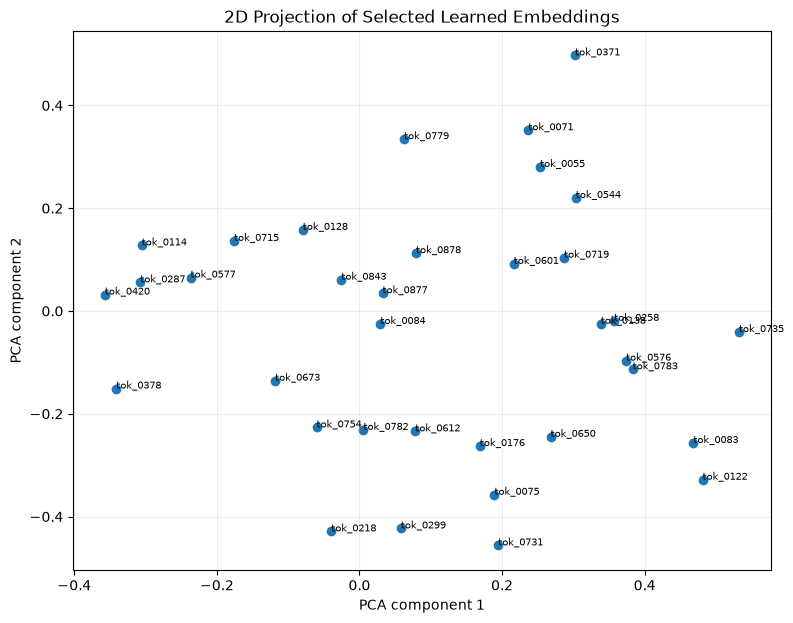

In [7]:
fig = plot_pca(E_norm, idx_to_token, n_show=35)
plt.show()

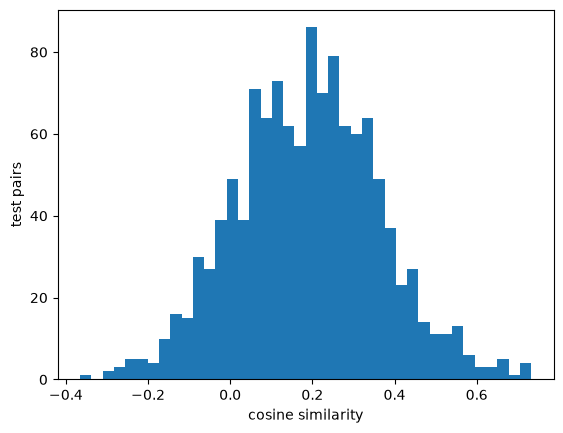

count    1200.000000
mean        0.188824
std         0.175550
min        -0.365129
25%         0.069577
50%         0.191885
75%         0.302393
max         0.732346
dtype: float64

In [8]:
# Distribution of raw test cosines: this is what each mapping in src/similarity.py reshapes.
cos = pair_cosines(E_norm, token_to_idx, test['token1'], test['token2'])
plt.hist(cos, bins=40)
plt.xlabel('cosine similarity'); plt.ylabel('test pairs'); plt.show()
pd.Series(cos).describe()